# Ex1: Ring Slot

The Vector Fitting feature is demonstrated using the *ring slot* example network from the scikit-rf `data` folder. Additional explanations and background information can be found in the [Vector Fitting tutorial](../../tutorials/VectorFitting.ipynb).

In [1]:
import matplotlib.pyplot as mplt
import numpy as np

import skrf
from skrf.vectorFitting import VectorFitting

To create a `VectorFitting` instance, a `Network` containing the frequency responses of the N-port is passed. In this example the *ring slot* is used, which can be loaded directly as a `Network` from scikit-rf:

In [2]:
nw = skrf.data.ring_slot
vf = VectorFitting(nw)

Now, the vector fit can be performed. The number of poles has to be specified, which depends on the *behaviour* of the responses. A smooth response would only require very few poles (2-5). In this case, 3 real poles are sufficient:

In [3]:
vf.vector_fit(n_poles_real=3, n_poles_cmplx=0)

/tmp/ipykernel_784768/3090911508.py:1: UserWarning: The fitted network is passive, but the vector fit is not passive. Consider running `passivity_enforce()` to enforce passivity before using this model.
  vf.vector_fit(n_poles_real=3, n_poles_cmplx=0)


As printed in the logging output (not shown), the pole relocation process converged quickly after just 5 iteration steps. This can also be checked with the convergence plot:

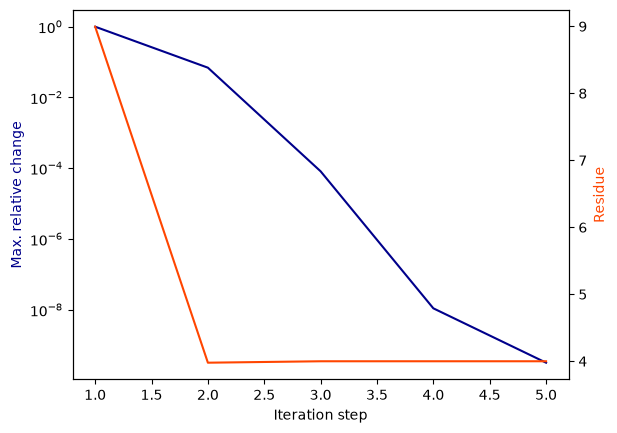

In [4]:
vf.plot_convergence()

The fitted model parameters are now stored in the class attributes `poles`, `residues`, `proportional_coeff` and `constant_coeff` for further use. To verify the result, the model response can be compared to the original network response. One option is to analyze the rms error magnitude, which should be smaller than 0.05 for a good fit:

In [5]:
vf.get_rms_error()

np.float64(0.003855803397460353)

As the model will return a response at any given frequency, it makes sense to also manually check its response outside the frequency range of the original samples by plotting it at lower and higher frequencies:

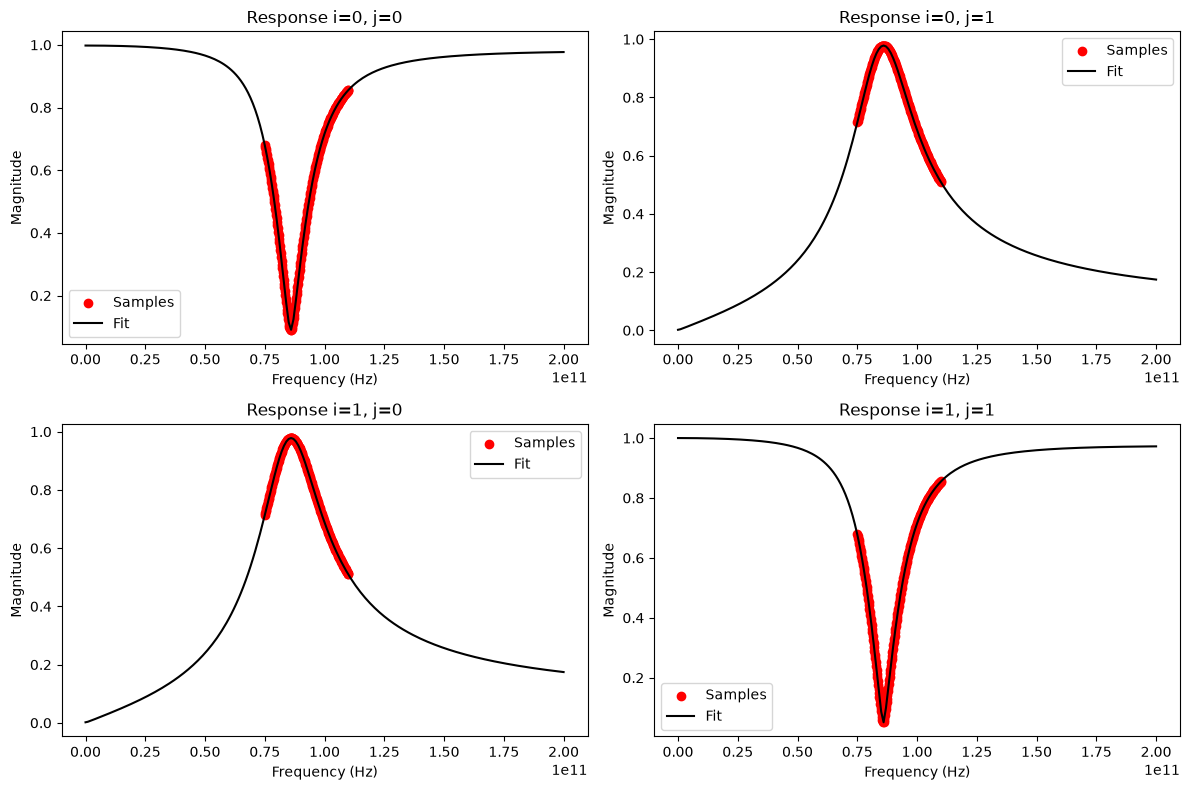

In [6]:
freqs1 = np.linspace(0, 200e9, 201)
fig, ax = mplt.subplots(2, 2)
fig.set_size_inches(12, 8)
vf.plot_s_mag(0, 0, freqs1, ax=ax[0][0]) # plot s11
vf.plot_s_mag(1, 0, freqs1, ax=ax[1][0]) # plot s21
vf.plot_s_mag(0, 1, freqs1, ax=ax[0][1]) # plot s12
vf.plot_s_mag(1, 1, freqs1, ax=ax[1][1]) # plot s22
fig.tight_layout()
mplt.show()

To use the model in a circuit simulation, an equivalent circuit can be created based on the fitting parameters. This is currently only implemented for SPICE, but the structure of the equivalent circuit can be adopted to any kind of circuit simulator. Attention: A UserWarning about a non-passive fit was printed (see output of vector_fit() above). The assessment and enforcement of model passivity is described in more detail in [this example](./vectorfitting_ex4_passivity.ipynb), which is important for certain use cases in circuit simulators, i.e. transient simulations.

`vf1.write_spice_subcircuit_s('/home/vinc/Desktop/ring_slot.sp')`

For a quick test, the subcircuit is included in a schematic in [QUCS-S](https://ra3xdh.github.io/) for AC simulation and S-parameter calculation based on the port voltages and currents (see the equations):
<img src="./ngspice_ringslot_schematic.svg" />

The simulation outputs from [ngspice](http://ngspice.sourceforge.net/) compare well to the plots above:
<img src="./ngspice_ringslot_sp_mag.svg" />

<img src="./ngspice_ringslot_sp_smith.svg" />